## PtyChee Constraints in Iterative Ptychography Demo

Running iterative ptychography with constraints

Author: Zeyu Wang <br>
October 2026

In [13]:
import numpy as np
from PtyChee.preProcessing import realSpace_bin
from PtyChee import run

4D-STEM data and parameters read in.<br>
Data (from https://doi.org/10.1038/s41586-025-09693-6) are provided as .zip file in the 'data' folder and need to be unzipped into .npy files before running.

In [14]:
folder_path = 'data/'
file = 'MAPbI3_HT200_a13_ss0.3_31_F3sum.npy'
data_4D = np.load(folder_path+file)
print(data_4D.shape)

Voltage = 200               # keV, accelerate votage
alpha = 0.013               # rad, semi convergence angle
scan_step = 0.3             # Å,   scan step size

defocus = -60               # Å,   defocus

(800, 800, 38, 38)


Simple preprocessing like cropping, binning and padding

In [15]:
data_4D = data_4D[-400:,-800:-400,:,:]
data_4D, scan_step = realSpace_bin(data_4D, scan_step, bin_factor=2)

real space bin 2 finished in 0.19199681282043457 s
data shape from (400, 400, 38, 38) to (200, 200, 38, 38)


You can use PtyChee.finRotate to calculate the optimized scan rotate angle, <br>
see 'run_ptyChee_01_findRotate_and_iCoM_MAPbI3_F3sum.ipynb'

In [16]:
scan_rotation_angle = -176   # degrees
scan_flip = False            # flip X axis or not

Run mix-state multi-slice ePIE with phase object approximation. The SNR of the results is better than only use soft threshold


ePIE
File: MAPbI3_HT200_a13_ss0.3_31_F3sum.npy

################ Experimental Information ################
Voltage: 200 kV
Alpha: 0.013 rad
scan step: 0.6 Å/pixel
defocus: -60 Å
scan rotation angle: -176 degrees
scan flip x: False

#################### Data Information ####################
data shape: (200, 200, 38, 38)
data type: int32
CBED intensity range: 0 – 14
average CBED intensity: 38.188724517822266
BF center_Y: 18.574074074074073
BF center_X: 18.675925925925927
BF threshold: 0.5
Aperture Radius: 5.775335216480246 pixels

################ Calculatied Calibration #################
reciprocal space pixel size: 0.08975319633381454 1/Å/pixel
real space pixel size: 0.2932016969714284 Å/pixel
ptycho move: 2.0463728764109717 pixels

############### Probe Mixstates Parameters ###############
Probe States: 2
Probe Generation Mode: Hermite
Probe Radius: 7.280109889280518 pixels

############# Object Multi-slice Parameters ##############
Object Slices: 6
recovered objFunc shape: (6, 493,

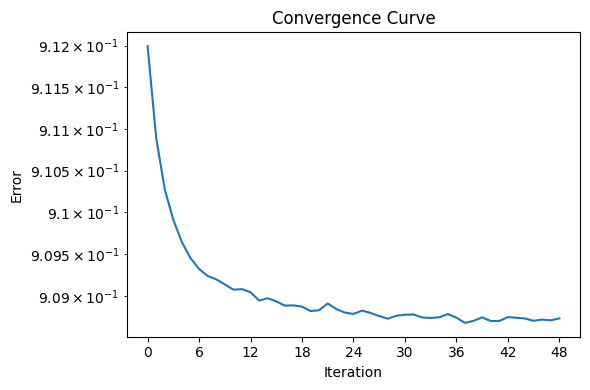

Object saving


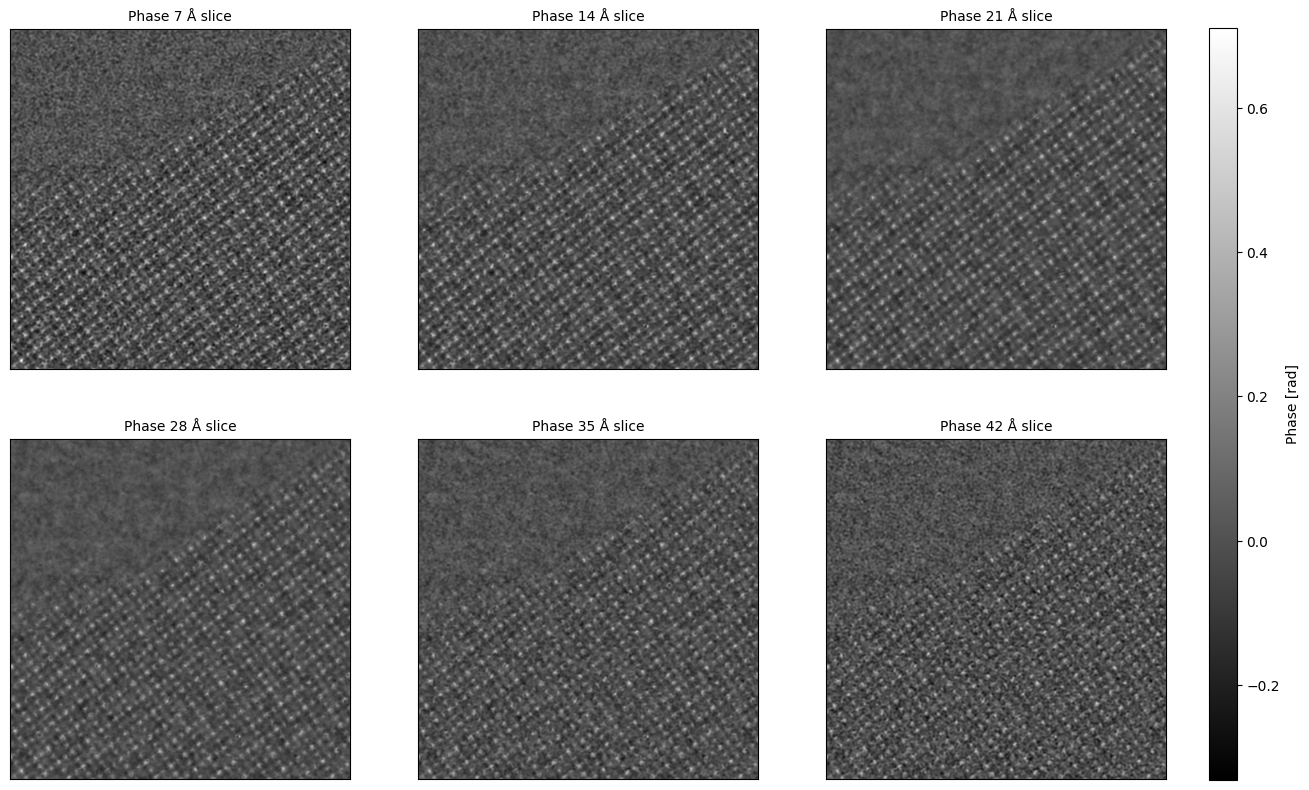

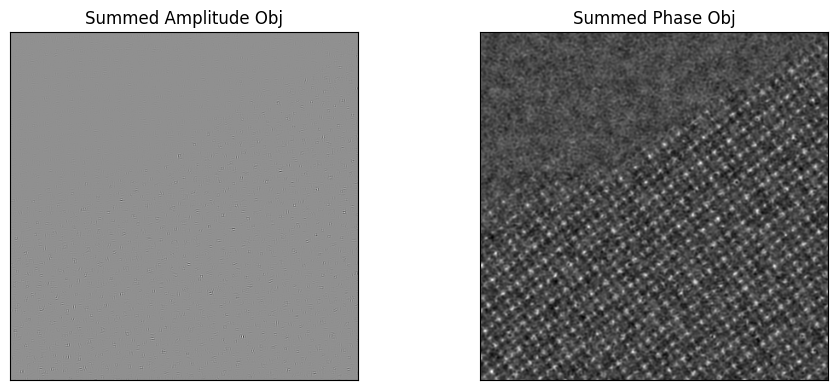

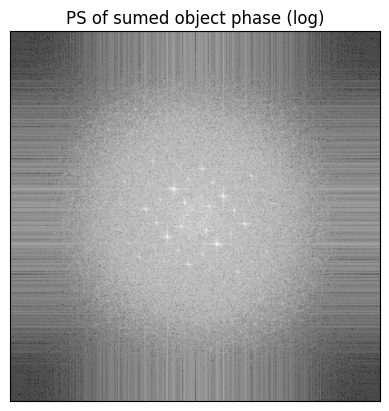

Probe saving


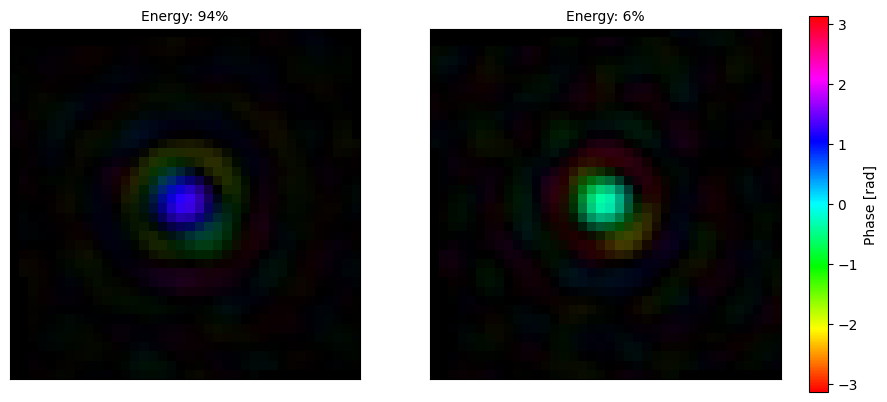

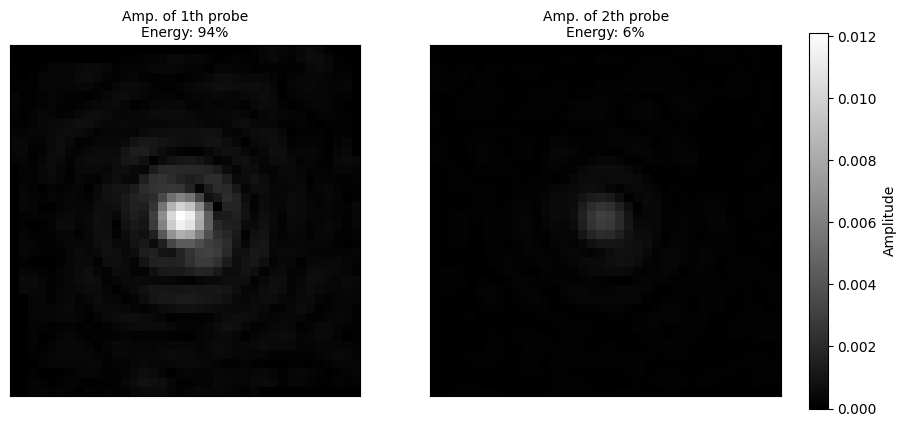

In [17]:
# ePIE
run.run_ePIE(file, data_4D, Voltage, alpha, scan_step, scan_rotation_angle, scan_flip, 
        defocus,
        n_state = 2,                    # probe states number
        n_slice = 6,                    # object slices number
        slice_thickness = 7,            # object slice thickness in Å
        iter_max = 50,                  # maximum iteration numner
        s_O = 10,                       # step size for updating Object Function
        s_P = 1,                        # step size for updating Probe Function
        n_block = 200,                  # block number：The CBEDs are divided into n_block blocks for batch computing    
        
        POA = True,                     # phase object approximation constraint
        l1_fft_softThreshold = 0.3,     # soft threshold for sparse constraint on object FFT
        zblur_std = 3,                  # z direction Gaussian blur standard deviation in Å

        #device = "cuda:0",             # specify the GPU device or use "cpu"
        save_results = False,           # set 'True' to save the results
);

Next is a showcase of all the constraints currently available in PtyChee. They are not all necessary on this data, but this example demonstrates how to turn them on.


ePIE
File: MAPbI3_HT200_a13_ss0.3_31_F3sum.npy

################ Experimental Information ################
Voltage: 200 kV
Alpha: 0.013 rad
scan step: 0.6 Å/pixel
defocus: -60 Å
scan rotation angle: -176 degrees
scan flip x: False

#################### Data Information ####################
data shape: (200, 200, 38, 38)
data type: int32
CBED intensity range: 0 – 14
average CBED intensity: 38.188724517822266
BF center_Y: 18.574074074074073
BF center_X: 18.675925925925927
BF threshold: 0.5
Aperture Radius: 5.775335216480246 pixels

################ Calculatied Calibration #################
reciprocal space pixel size: 0.08975319633381454 1/Å/pixel
real space pixel size: 0.2932016969714284 Å/pixel
ptycho move: 2.0463728764109717 pixels

############### Probe Mixstates Parameters ###############
Probe States: 2
Probe Generation Mode: Hermite
Probe Radius: 7.280109889280518 pixels

############# Object Multi-slice Parameters ##############
Object Slices: 6
recovered objFunc shape: (6, 493,

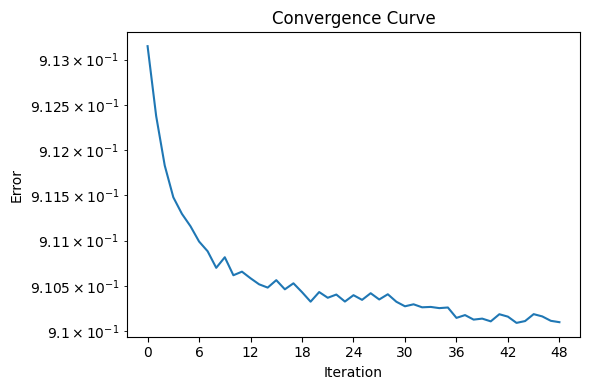

Object saving


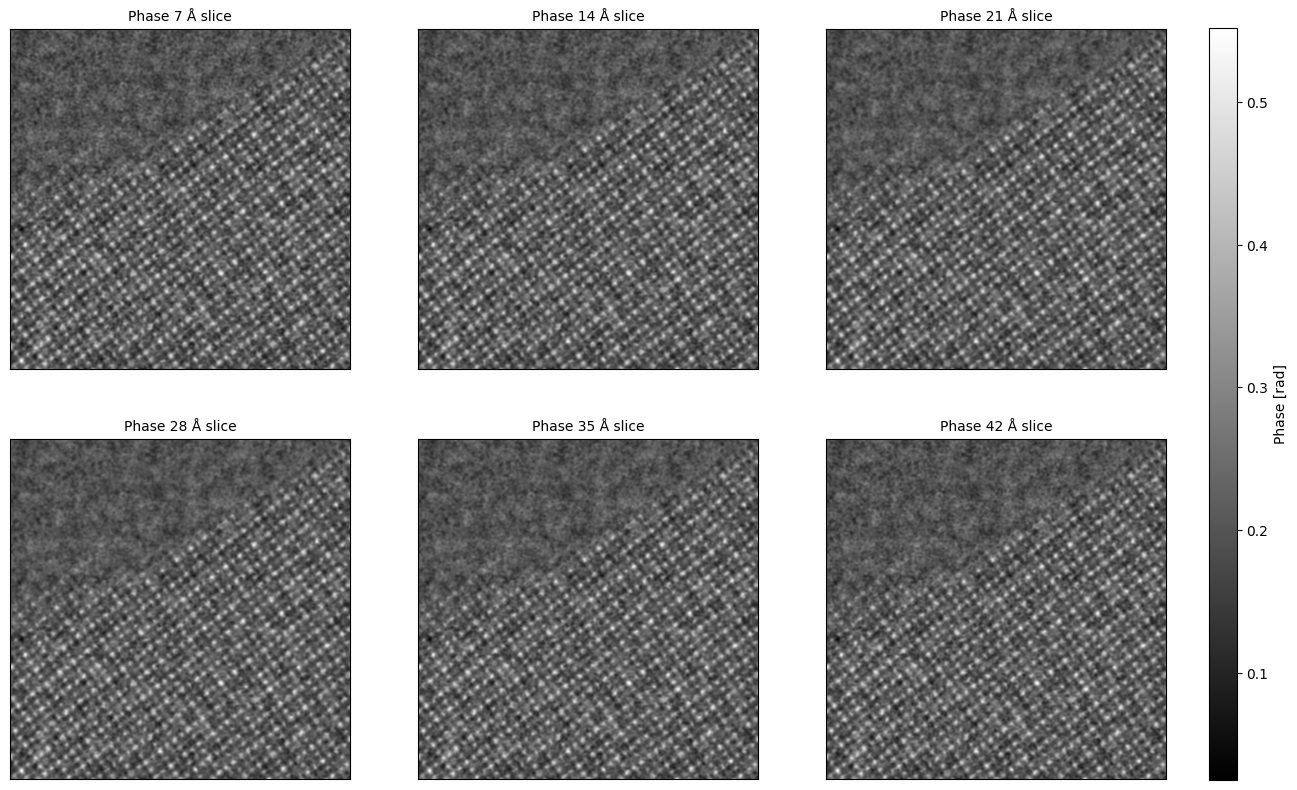

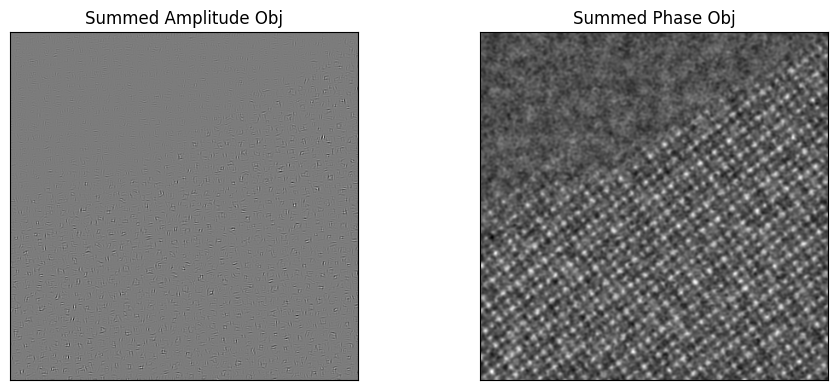

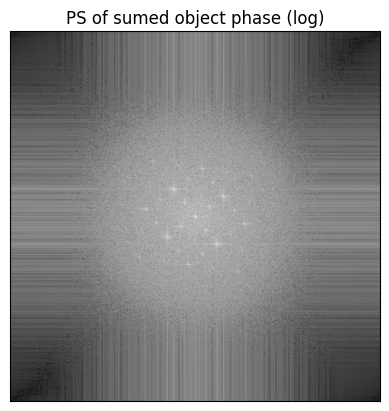

Probe saving


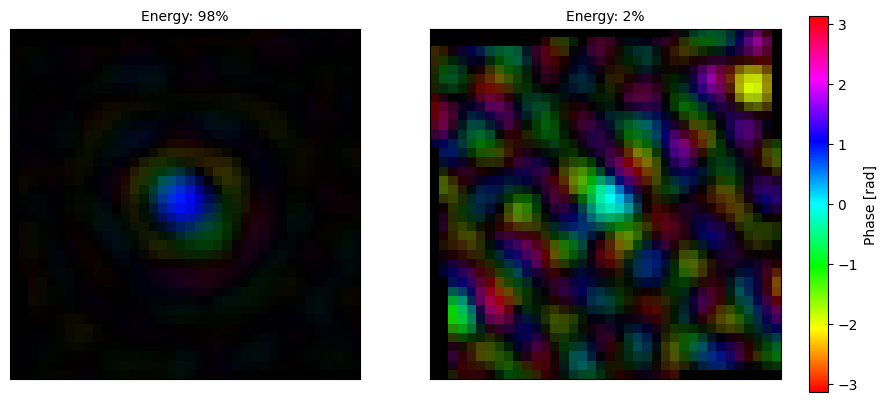

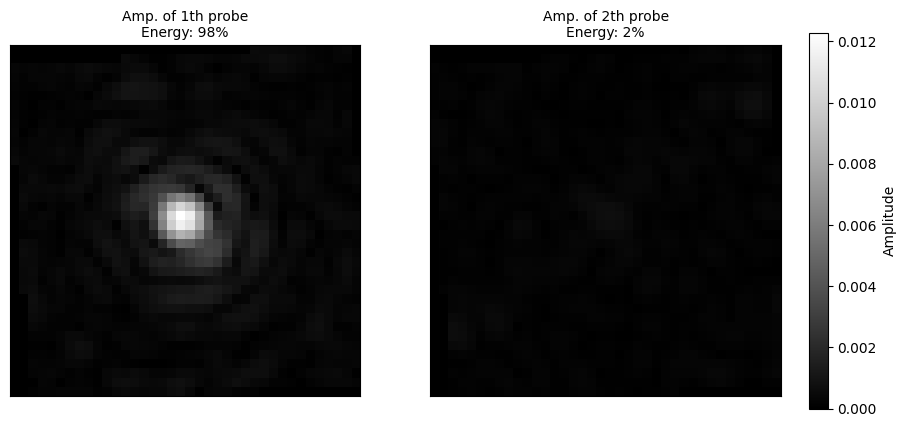

In [ ]:
# ePIE
run.run_ePIE(file, data_4D, Voltage, alpha, scan_step, scan_rotation_angle, scan_flip, 
        defocus,
        n_state = 2,                    # probe states number
        n_slice = 6,                    # object slices number
        slice_thickness = 7,            # object slice thickness in Å
        iter_max = 50,                  # maximum iteration numner
        s_O = 10,                       # step size for updating Object Function
        s_P = 1,                        # step size for updating Probe Function
        n_block = 200,                  # block number：The CBEDs are divided into n_block blocks for batch computing    
        
        POA = True,                     # phase object approximation constraint
        rh_positive_phase = True,       # rh constraint: If True, all negative values in the phase result are clipped
        FFT_phase_offset = 0.01,        # phase offset to remove donut shape

        l2_fft_lambdaTikhonov = 0.3,    # Tikhonov constraint on object (l2 constraint on object FFT)              
        l1_fft_softThreshold = 0.3,     # soft threshold for sparse constraint on object FFT
        l0_fft_hardThreshold = 0.01,    # hard threshold for sparse constraint on object FFT

        kz_regularization = 0.5,        # kz constraint for the 'missing cone problem', chose one between this and 'zblur_std' constraint, there is no need to use both of these constraints simultaneously.
        # zblur_std = 3,                  # z direction Gaussian blur standard deviation in Å

        #device = "cuda:0",             # specify the GPU device or use "cpu"
        save_results = False,           # set 'True' to save the results
);